# 1. Characterization of Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns #visualisation
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [2]:
df= pd.read_csv('NPHA-doctor-visits.csv')

In [3]:
#  Target=Trouble Sleeping (0,1)
df['Trouble Sleeping'] = df['Trouble Sleeping'].apply(lambda x: 1 if x > 1 else 0)
print("Trouble Sleeping баганын утгууд:", df['Trouble Sleeping'].unique())

Trouble Sleeping баганын утгууд: [1 0]


In [4]:
df.head(5)

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
0,3,2,4,3,3,3,0,0,0,0,1,1,3,1,2
1,2,2,4,2,3,3,1,0,0,1,0,1,3,1,1
2,3,2,3,2,3,3,0,0,0,0,1,1,3,4,1
3,1,2,3,2,3,3,0,0,0,1,0,1,3,4,2
4,3,2,3,3,3,3,1,0,0,0,0,1,3,1,2


In [5]:
df.tail(5)

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
709,2,2,2,2,2,3,0,0,0,1,0,1,3,1,1
710,3,2,2,2,2,2,1,0,0,0,1,1,3,1,2
711,3,2,4,2,3,3,0,0,0,0,0,1,3,1,1
712,3,2,3,1,3,3,1,0,1,1,1,1,3,1,2
713,2,2,3,2,2,1,1,0,1,1,0,1,3,1,1


In [6]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 15 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   Number of Doctors Visited                   714 non-null    int64
 1   Age                                         714 non-null    int64
 2   Phyiscal Health                             714 non-null    int64
 3   Mental Health                               714 non-null    int64
 4   Dental Health                               714 non-null    int64
 5   Employment                                  714 non-null    int64
 6   Stress Keeps Patient from Sleeping          714 non-null    int64
 7   Medication Keeps Patient from Sleeping      714 non-null    int64
 8   Pain Keeps Patient from Sleeping            714 non-null    int64
 9   Bathroom Needs Keeps Patient from Sleeping  714 non-null    int64
 10  Uknown Keeps Patient from Sleeping          714 n

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Number of Doctors Visited,714.0,2.112045,0.683441,1.0,2.0,2.0,3.0,3.0
Age,714.0,2.000000,0.000000,2.0,2.0,2.0,2.0,2.0
Phyiscal Health,714.0,2.794118,0.900939,-1.0,2.0,3.0,3.0,5.0
Mental Health,714.0,1.988796,0.939928,-1.0,1.0,2.0,3.0,5.0
Dental Health,714.0,3.009804,1.361117,-1.0,2.0,3.0,4.0,6.0
Employment,714.0,2.806723,0.586582,1.0,3.0,3.0,3.0,4.0
Stress Keeps Patient from Sleeping,714.0,0.247899,0.432096,0.0,0.0,0.0,0.0,1.0
Medication Keeps Patient from Sleeping,714.0,0.056022,0.230126,0.0,0.0,0.0,0.0,1.0
Pain Keeps Patient from Sleeping,714.0,0.218487,0.413510,0.0,0.0,0.0,0.0,1.0
Bathroom Needs Keeps Patient from Sleeping,714.0,0.504202,0.500333,0.0,0.0,1.0,1.0,1.0


# 2. Data Pre-processing

In [8]:
df.isnull().sum()

Number of Doctors Visited                     0
Age                                           0
Phyiscal Health                               0
Mental Health                                 0
Dental Health                                 0
Employment                                    0
Stress Keeps Patient from Sleeping            0
Medication Keeps Patient from Sleeping        0
Pain Keeps Patient from Sleeping              0
Bathroom Needs Keeps Patient from Sleeping    0
Uknown Keeps Patient from Sleeping            0
Trouble Sleeping                              0
Prescription Sleep Medication                 0
Race                                          0
Gender                                        0
dtype: int64

In [9]:
# . Hidden missing values ('?', 'Na', 'UnKnown') to NaN
hidden = ['?', 'Na', 'UnKnown']
text_cols = [c for c in df.select_dtypes(include=['object', 'str']).columns if c != 'Target']

nan_before = df.isnull().sum().sum()
for col in text_cols:
    n = df[col].isin(hidden).sum()
    if n > 0:
        print(f"{col}: {n} hidden missing values")

df[text_cols] = df[text_cols].replace(hidden, np.nan)

nan_after = df.isnull().sum().sum()
print(f"\nMissing values before: {nan_before}")
print(f"Missing values after:  {nan_after}")
print(f"Newly revealed hidden missing values: {nan_after - nan_before}")


Missing values before: 0
Missing values after:  0
Newly revealed hidden missing values: 0


In [10]:
hidden = ['?', 'Na', 'UnKnown']
remaining = {c: int(df[c].isin(hidden).sum()) for c in text_cols if df[c].isin(hidden).sum() > 0}
print("Hidden values remaining:", remaining)     
print("Total NaN:", df.isnull().sum().sum())   

Hidden values remaining: {}
Total NaN: 0


In [11]:
df.duplicated().sum()

np.int64(67)

In [12]:
df = df.drop_duplicates()
print(df.duplicated().sum()) 
print(df.shape)             

0
(647, 15)


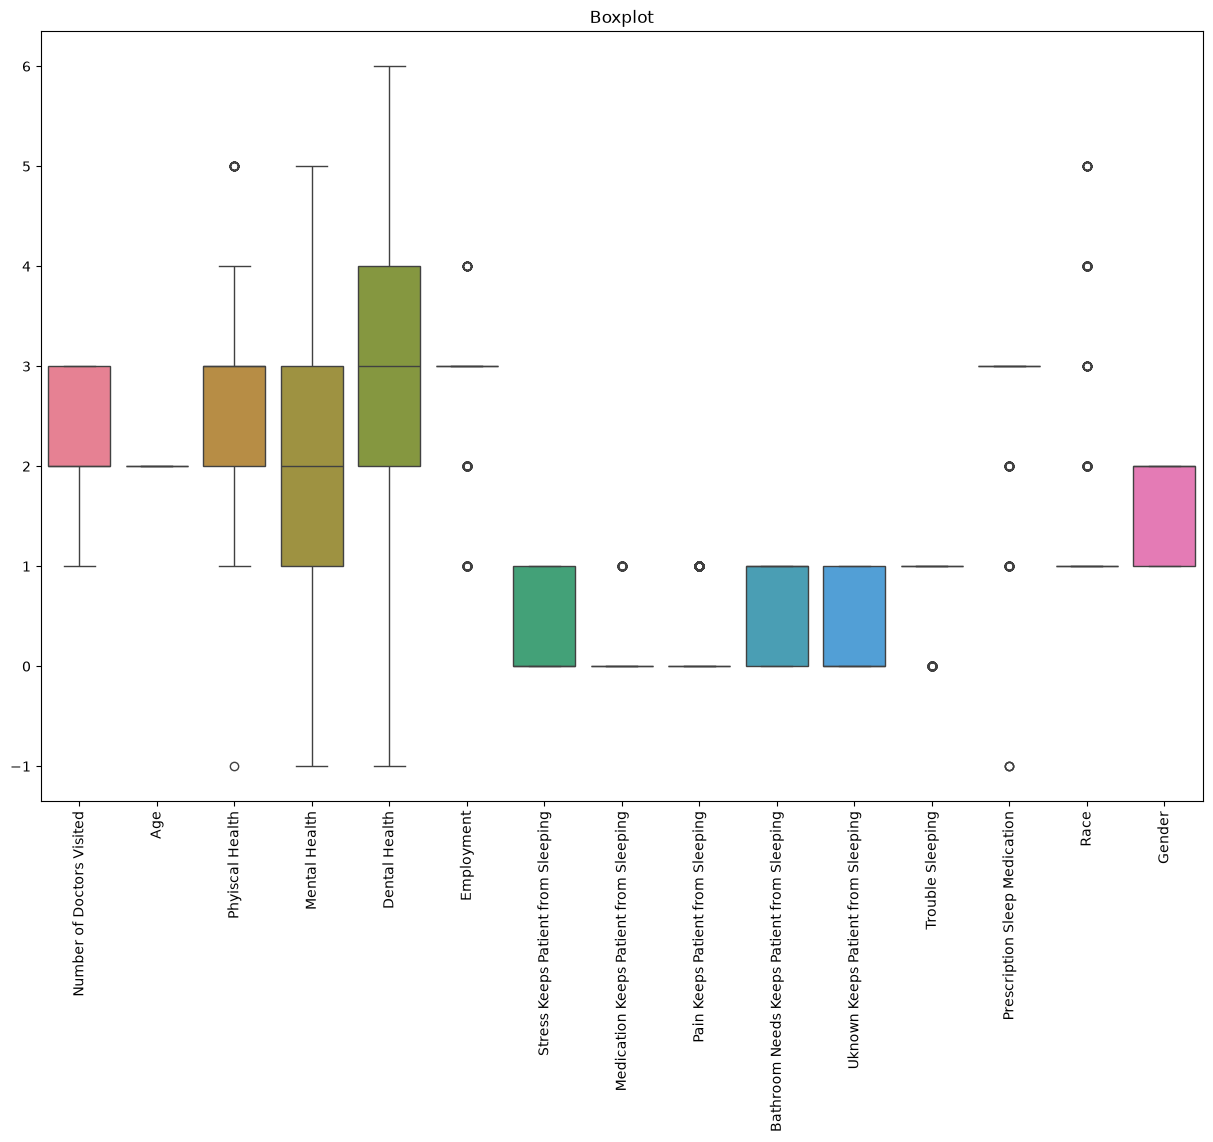

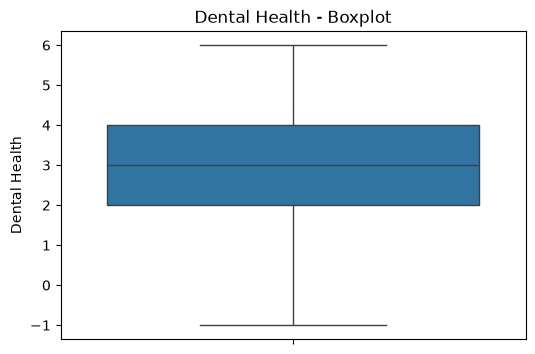

In [13]:
# 1 Outliers detection
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))
sns.boxplot(data=df)
plt.xticks(rotation=90) 
plt.title("Boxplot")
plt.show()
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['Dental Health'])
plt.title("Dental Health - Boxplot")
plt.show()

In [14]:
df_cleaned = df.copy() 
# check outliers columns
cols_to_check = ['Age', 'Physical Health', 'Mental Health', 'Dental Health']

In [15]:
# remove each column outlier
for col in cols_to_check:
    if col in df_cleaned.columns:
        Q1 = df_cleaned[col].quantile(0.25)
        Q3 = df_cleaned[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 3 * IQR
        upper_bound = Q3 + 3 * IQR
        
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]

print("Rows before removal:", df.shape[0])
print("Rows after removal:", df_cleaned.shape[0])

Rows before removal: 647
Rows after removal: 647


In [16]:
df_cleaned.to_csv('cleaned_dataset.csv', index=False)
print("cleaned_data")

cleaned_data


In [17]:
# 1. Target (y) болон Features (X)
X = df_cleaned.drop('Trouble Sleeping', axis=1)
y = df_cleaned['Trouble Sleeping']

# 2. y дотор зөвхөн 0 болон 1 байгаа эсэхийг шалгах
print("y баганын утгууд (0 болон 1 байх ёстой):", y.unique())

# 3. Өгөгдлийг 95:5 харьцаагаар дахин хуваах
X_train_95, X_test_5, y_train_95, y_test_5 = train_test_split(X, y, test_size=0.05, random_state=42)

print("X_train хэмжээ:", X_train_95.shape)
print("X_test хэмжээ:", X_test_5.shape)

y баганын утгууд (0 болон 1 байх ёстой): [1 0]
X_train хэмжээ: (614, 14)
X_test хэмжээ: (33, 14)


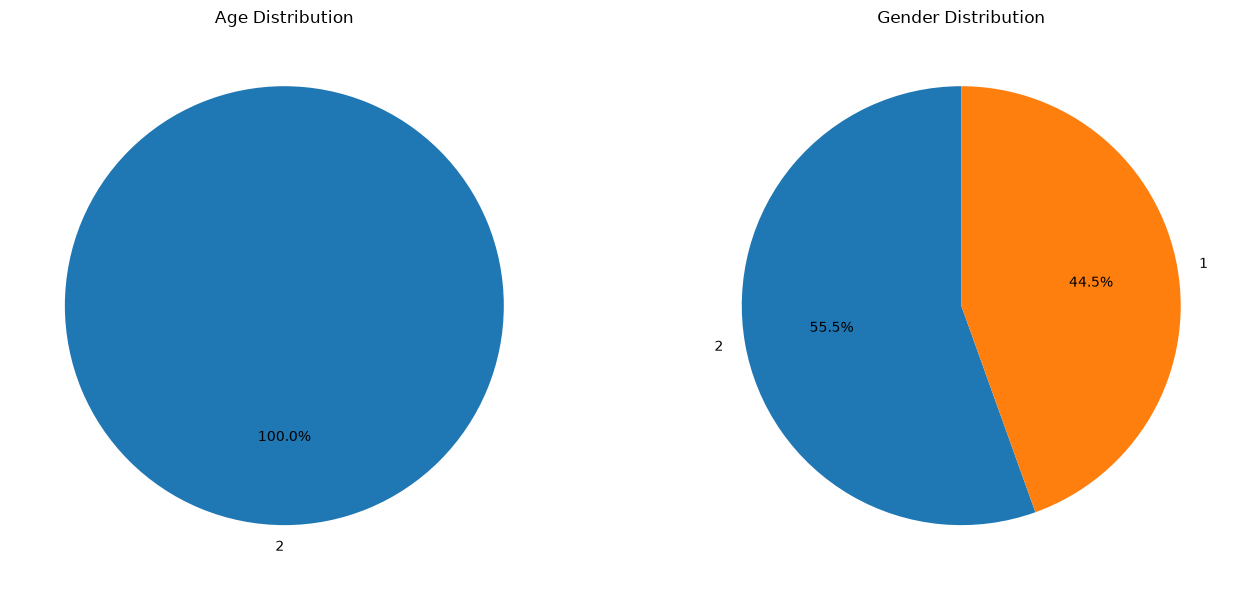

In [18]:
import matplotlib.pyplot as plt

age_counts = df['Age'].value_counts()
gender_counts = df['Gender'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(age_counts, labels=age_counts.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Age Distribution')

axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Gender Distribution')

plt.tight_layout()
plt.show()

In [19]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# (Gender)Label Encoding
le = LabelEncoder()
df_cleaned['Gender'] = le.fit_transform(df_cleaned['Gender'])

# (Race)One-Hot Encoding 
df_cleaned = pd.get_dummies(df_cleaned, columns=['Race'], drop_first=True)

print("After Encoding :")
print(df_cleaned.columns.tolist())

After Encoding :
['Number of Doctors Visited', 'Age', 'Phyiscal Health', 'Mental Health', 'Dental Health', 'Employment', 'Stress Keeps Patient from Sleeping', 'Medication Keeps Patient from Sleeping', 'Pain Keeps Patient from Sleeping', 'Bathroom Needs Keeps Patient from Sleeping', 'Uknown Keeps Patient from Sleeping', 'Trouble Sleeping', 'Prescription Sleep Medication', 'Gender', 'Race_2', 'Race_3', 'Race_4', 'Race_5']


In [20]:
from sklearn.model_selection import train_test_split

# 'Trouble Sleeping'- X 
X = df_cleaned.drop('Trouble Sleeping', axis=1)

# 'Trouble Sleeping' -y 
y = df_cleaned['Trouble Sleeping']

print("X:", X.shape)
print("y:", y.shape)

X: (647, 17)
y: (647,)


In [21]:
# 95:5
X_train_95, X_test_5, y_train_95, y_test_5 = train_test_split(X, y, test_size=0.20, random_state=42)

print("95:5")
print(f"Train size: {X_train_95.shape[0]}")
print(f"Test size:  {X_test_5.shape[0]}")

95:5
Train size: 517
Test size:  130


In [22]:
# 85:15 
# test_size=0.15 нь 15% test, 85% (train) 
X_train_85, X_test_15, y_train_85, y_test_15 = train_test_split(X, y, test_size=0.15, random_state=42)

print("85:15")
print(f"Train size: {X_train_85.shape[0]}")
print(f"Test size:  {X_test_15.shape[0]}")

85:15
Train size: 549
Test size:  98


In [23]:
# 3. 75:25 
# test_size=0.30 нь 30% тест, 70% сургалт (train) болно
X_train_75, X_test_25, y_train_75, y_test_25 = train_test_split(X, y, test_size=0.25, random_state=42)

print("75:25")
print(f"Train size: {X_train_75.shape[0]}")
print(f"Test size:  {X_test_25.shape[0]}")

75:25
Train size: 485
Test size:  162


In [24]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [25]:
from sklearn.metrics import accuracy_score, classification_report
# 95:5
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 5 % training data
    classifier.fit(X_train_95, y_train_95)
    
    # 2. Predict on the 5% test set
    y_pred = classifier.predict(X_test_5)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_5, y_pred)
    report = classification_report(y_test_5, y_pred, output_dict=True, zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.892308   0.796213 0.892308  0.841526
         Random Forest  0.884615   0.836867 0.884615  0.849897
   Logistic Regression  0.900000   0.910078 0.900000  0.859320
Support Vector Machine  0.892308   0.796213 0.892308  0.841526


In [26]:
from sklearn.metrics import accuracy_score, classification_report
# 85:15
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 70% training data
    classifier.fit(X_train_85, y_train_85)
    
    # 2. Predict on the 15% test set
    y_pred = classifier.predict(X_test_15)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_15, y_pred)
    report = classification_report(y_test_15, y_pred, output_dict=True,zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.887755   0.788109 0.887755  0.834970
         Random Forest  0.877551   0.787082 0.877551  0.829858
   Logistic Regression  0.887755   0.788109 0.887755  0.834970
Support Vector Machine  0.887755   0.788109 0.887755  0.834970


In [27]:
from sklearn.metrics import accuracy_score, classification_report
# 75:25
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 75% training data
    classifier.fit(X_train_75, y_train_75)
    
    # 2. Predict on the 25 test set
    y_pred = classifier.predict(X_test_25)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_25, y_pred)
    report = classification_report(y_test_25, y_pred, output_dict=True,zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.888889   0.790123 0.888889  0.836601
         Random Forest  0.870370   0.814862 0.870370  0.836535
   Logistic Regression  0.901235   0.911111 0.901235  0.864327
Support Vector Machine  0.888889   0.790123 0.888889  0.836601


In [28]:
# 1. Logistic Regression 
lr_model = LogisticRegression(random_state=42, max_iter=1000)

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],     
    'solver': ['liblinear', 'lbfgs'],  
    'class_weight': ['balanced', None]  
}

# 3. GridSearchCV 
grid_search_lr = GridSearchCV(
    estimator=lr_model, 
    param_grid=param_grid_lr, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1, 
    verbose=1
)

In [29]:
from sklearn.metrics import accuracy_score

# GridSearchCV-75:25 
print("GridSearchCV (Logistic Regression)")
grid_search_lr.fit(X_train_75, y_train_75)

#Cross-Validation
print("\n(Logistic Regression)")
print("Best Parameters:", grid_search_lr.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search_lr.best_score_, 4))

GridSearchCV (Logistic Regression)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

(Logistic Regression)
Best Parameters: {'C': 0.01, 'class_weight': None, 'solver': 'liblinear'}
Best Cross-Validation Accuracy: 0.9052


In [30]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Random Forest 
rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train_75, y_train_75)


importance = pd.Series(rf.feature_importances_, index=X_train_95.columns).nlargest(5)
print("Best 5 factor:\n", importance)

Best 5 factor:
 Dental Health                0.168718
Phyiscal Health              0.125622
Mental Health                0.120270
Employment                   0.092647
Number of Doctors Visited    0.076249
dtype: float64


In [32]:
best_lr = grid_search_lr.best_estimator_
y_pred_tuned_lr = best_lr.predict(X_test_25)

#  Accuracy
final_accuracy_lr = accuracy_score(y_test_25, y_pred_tuned_lr)

print(f" Beforev Accuracy (Logistic Regression): 90.52%")
print(f"After Accuracy (Logistic Regression): {round(final_accuracy_lr * 100, 2)}%")

 Beforev Accuracy (Logistic Regression): 90.52%
After Accuracy (Logistic Regression): 88.89%


References

https://archive.ics.uci.edu/dataset/936/national+poll+on+healthy+aging+(npha)